# 100 Sports Image Classification

This is a CNN classification project.

We have images from 100 different sports. Each image is a 224x224x3 jpg and the data is already separated into train, valid and test directories.

I will train two models on the same split. The first is our own CNN, built from scratch with three convolution blocks. The second is EfficientNetB0 with ImageNet weights. A small network has a hard time with 100 similar classes, and these photos are already 224x224, so EfficientNetB0 is the transfer model I want here. Its new head trains first, then the last 30 layers are fine-tuned. The test directory stays out of training. At the end I will compare accuracy and F1 and save both models.


In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gpiosenka/sports-classification")

print("Path to dataset files:", path)


100%|██████████| 424M/424M [02:15<00:00, 3.29MB/s] 

Extracting files...


Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\gpiosenka\sports-classification\versions\9


In [2]:
import os
import tensorflow as tf

tf.keras.utils.set_random_seed(42)


def find_named_dir(root, folder_name):
    for current, dirnames, _ in os.walk(root):
        if folder_name in dirnames:
            return os.path.join(current, folder_name)


train_dir = find_named_dir(path, "train")
test_dir = find_named_dir(path, "test")
val_dir = find_named_dir(path, "valid")

class_names = sorted([f for f in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, f))])
print("Classes Count:", len(class_names))
print(class_names[:10], "...")

counts = [len(os.listdir(os.path.join(train_dir, c))) for c in class_names]
print("Train images:", sum(counts), "| smallest class:", min(counts), "| largest class:", max(counts))


Classes Count: 100
['air hockey', 'ampute football', 'archery', 'arm wrestling', 'axe throwing', 'balance beam', 'barell racing', 'baseball', 'basketball', 'baton twirling'] ...
Train images: 13493 | smallest class: 59 | largest class: 191


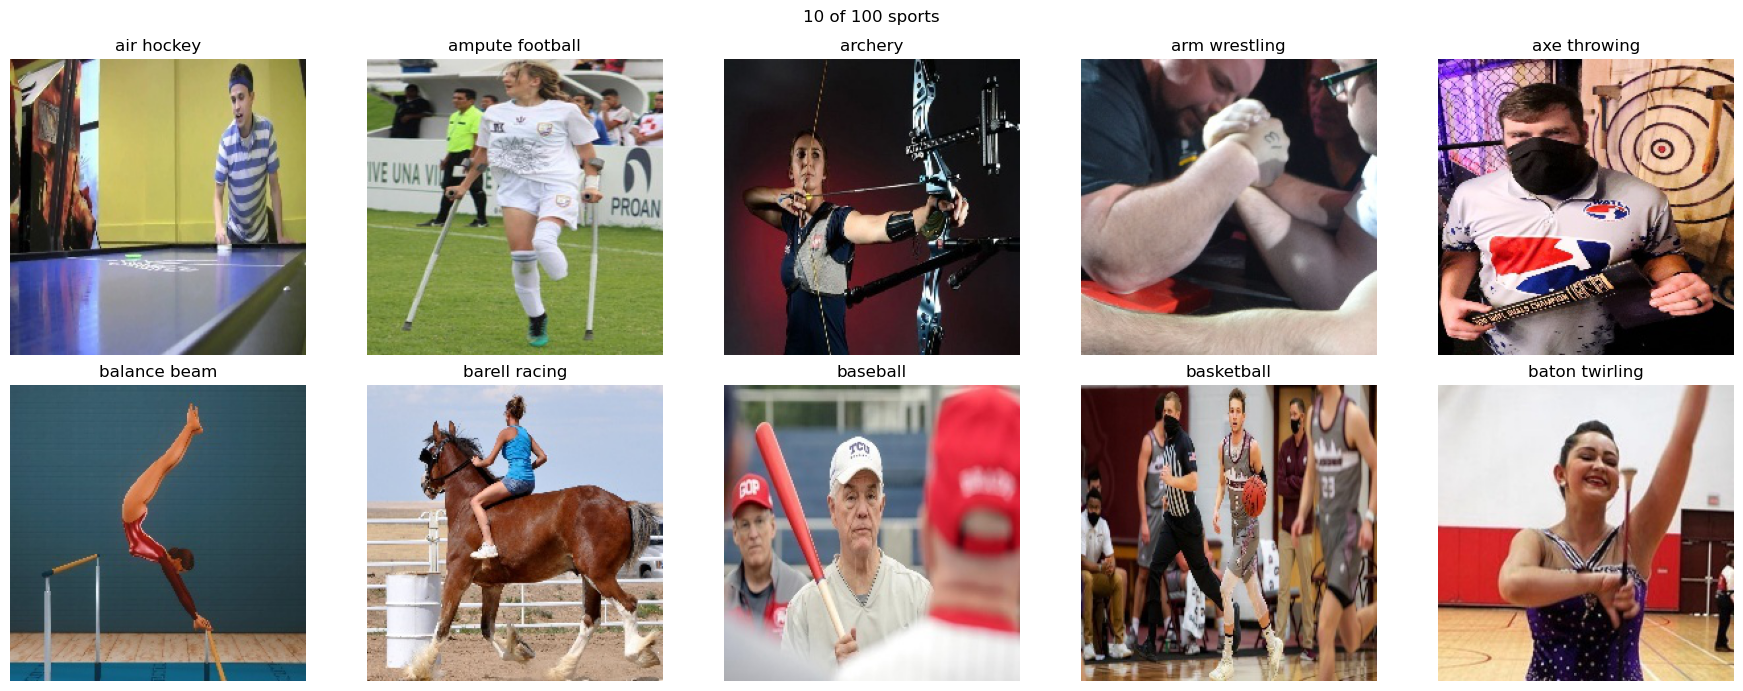

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 7))
for i, class_name in enumerate(class_names[:10]):
    class_path = os.path.join(train_dir, class_name)
    image_path = os.path.join(class_path, os.listdir(class_path)[0])
    image = plt.imread(image_path)
    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")
plt.suptitle("10 of 100 sports")
plt.tight_layout()
plt.show()


In [4]:
from PIL import Image

sample_path = os.path.join(train_dir, class_names[0], os.listdir(os.path.join(train_dir, class_names[0]))[0])
print(class_names[0], "->", Image.open(sample_path).size, Image.open(sample_path).mode)


air hockey -> (224, 224) RGB


In [5]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=True, seed=42,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False,
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False,
)

class_names = train_ds.class_names
print(class_names)
print("Classes Count:", len(class_names))

train_ds = train_ds.shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


Found 13492 files belonging to 100 classes.
Found 500 files belonging to 100 classes.
Found 500 files belonging to 100 classes.
['air hockey', 'ampute football', 'archery', 'arm wrestling', 'axe throwing', 'balance beam', 'barell racing', 'baseball', 'basketball', 'baton twirling', 'bike polo', 'billiards', 'bmx', 'bobsled', 'bowling', 'boxing', 'bull riding', 'bungee jumping', 'canoe slamon', 'cheerleading', 'chuckwagon racing', 'cricket', 'croquet', 'curling', 'disc golf', 'fencing', 'field hockey', 'figure skating men', 'figure skating pairs', 'figure skating women', 'fly fishing', 'football', 'formula 1 racing', 'frisbee', 'gaga', 'giant slalom', 'golf', 'hammer throw', 'hang gliding', 'harness racing', 'high jump', 'hockey', 'horse jumping', 'horse racing', 'horseshoe pitching', 'hurdles', 'hydroplane racing', 'ice climbing', 'ice yachting', 'jai alai', 'javelin', 'jousting', 'judo', 'lacrosse', 'log rolling', 'luge', 'motorcycle racing', 'mushing', 'nascar racing', 'olympic wrest

In [7]:
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

scratch_callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-6),
]

scratch_model = tf.keras.Sequential()
scratch_model.add(layers.Input(shape=(224, 224, 3)))
scratch_model.add(layers.Rescaling(1.0 / 255))
scratch_model.add(layers.RandomFlip("horizontal"))
scratch_model.add(layers.RandomRotation(0.08))
scratch_model.add(layers.RandomZoom(0.15))
scratch_model.add(layers.Conv2D(32, (3, 3), activation="relu"))
scratch_model.add(layers.BatchNormalization())
scratch_model.add(layers.MaxPooling2D())
scratch_model.add(layers.Conv2D(64, (3, 3), activation="relu"))
scratch_model.add(layers.BatchNormalization())
scratch_model.add(layers.MaxPooling2D())
scratch_model.add(layers.Conv2D(128, (3, 3), activation="relu"))
scratch_model.add(layers.BatchNormalization())
scratch_model.add(layers.MaxPooling2D())
scratch_model.add(layers.GlobalAveragePooling2D())
scratch_model.add(layers.Dense(256, activation="relu"))
scratch_model.add(layers.Dropout(0.5))
scratch_model.add(layers.Dense(128, activation="relu"))
scratch_model.add(layers.Dense(len(class_names), activation="softmax"))

scratch_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
scratch_model.summary()
history_scratch = scratch_model.fit(
    train_ds, validation_data=val_ds, epochs=25, callbacks=scratch_callbacks, verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │        12,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 172,964 (675.64 KB)

 Trainable params: 172,516 (673.89 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/25


c:\Users\Administrator\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


422/422 ━━━━━━━━━━━━━━━━━━━━ 137s 315ms/step - accuracy: 0.0798 - loss: 4.0406 - val_accuracy: 0.0500 - val_loss: 4.7302 - learning_rate: 0.0010
Epoch 2/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 134s 315ms/step - accuracy: 0.1451 - loss: 3.5024 - val_accuracy: 0.1760 - val_loss: 3.3586 - learning_rate: 0.0010
Epoch 3/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 134s 315ms/step - accuracy: 0.1829 - loss: 3.2734 - val_accuracy: 0.1760 - val_loss: 3.4589 - learning_rate: 0.0010
Epoch 4/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 137s 320ms/step - accuracy: 0.2200 - loss: 3.0722 - val_accuracy: 0.1760 - val_loss: 3.3452 - learning_rate: 0.0010
Epoch 5/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 136s 318ms/step - accuracy: 0.2429 - loss: 2.9231 - val_accuracy: 0.2080 - val_loss: 3.3246 - learning_rate: 0.0010
Epoch 6/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 136s 319ms/step - accuracy: 0.2836 - loss: 2.7779 - val_accuracy: 0.3120 - val_loss: 2.7277 - learning_rate: 0.0010
Epoch 7/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 136s 319ms/step - accuracy: 0.3083 

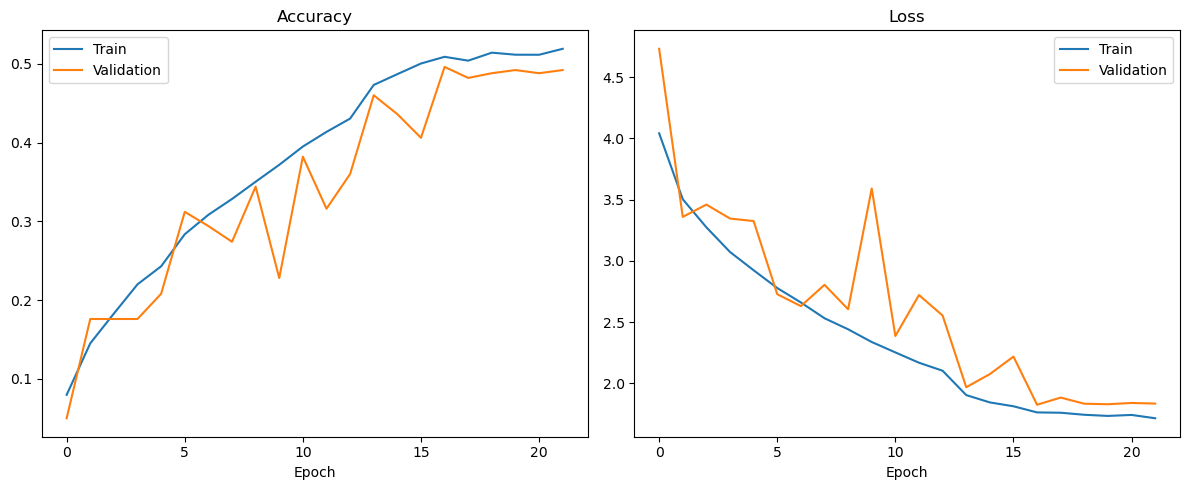

In [8]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_scratch.history["accuracy"], label="Train")
plt.plot(history_scratch.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_scratch.history["loss"], label="Train")
plt.plot(history_scratch.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()


Our CNN
Accuracy : 0.502
Precision: 0.5274979070636965
Recall   : 0.502
F1       : 0.4704331949664431
                       precision    recall  f1-score   support

           air hockey       1.00      0.20      0.33         5
      ampute football       0.00      0.00      0.00         5
              archery       0.25      0.20      0.22         5
        arm wrestling       0.50      0.20      0.29         5
         axe throwing       0.75      0.60      0.67         5
         balance beam       0.20      0.60      0.30         5
        barell racing       0.67      0.40      0.50         5
             baseball       1.00      0.40      0.57         5
           basketball       0.25      0.20      0.22         5
       baton twirling       1.00      0.20      0.33         5
            bike polo       0.50      0.20      0.29         5
            billiards       1.00      1.00      1.00         5
                  bmx       0.00      0.00      0.00         5
              b

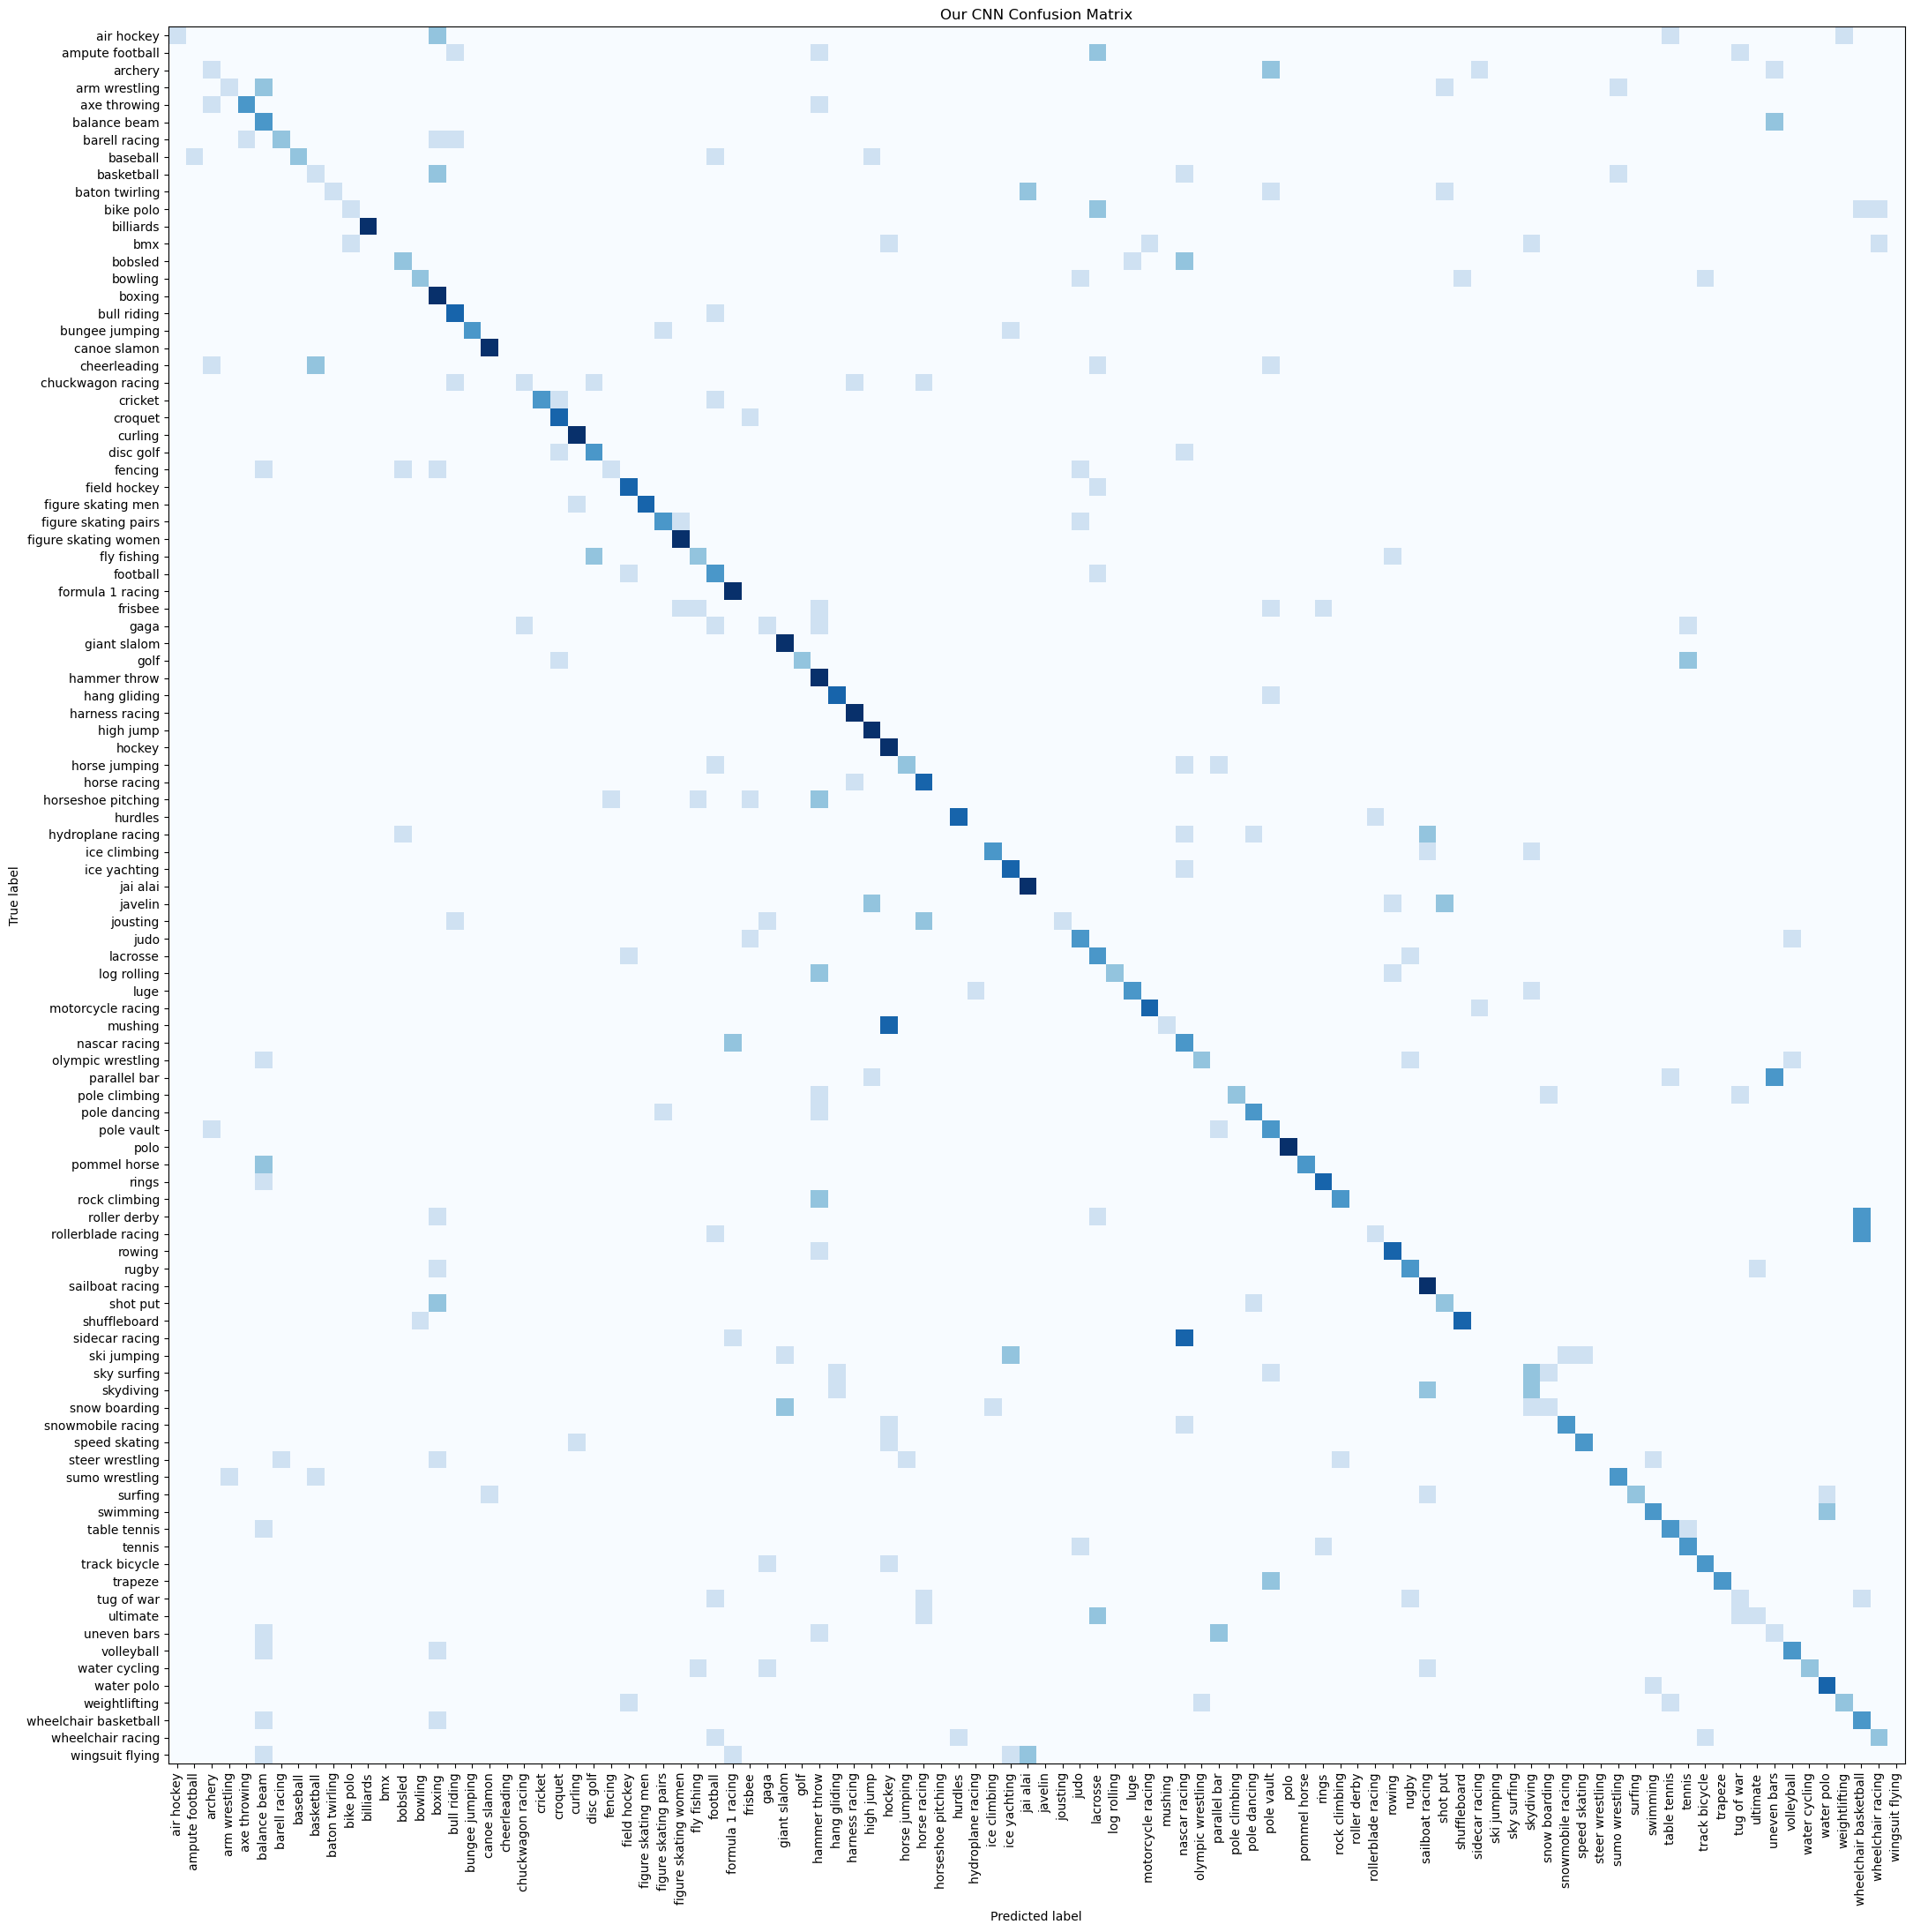

In [9]:
import numpy as np
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score)

y_true_scratch = []
y_pred_scratch = []

for images, labels in test_ds:
    preds = scratch_model.predict(images, verbose=0)
    y_true_scratch.extend(np.argmax(labels.numpy(), axis=1))
    y_pred_scratch.extend(np.argmax(preds, axis=1))

y_true_scratch = np.array(y_true_scratch)
y_pred_scratch = np.array(y_pred_scratch)

scratch_acc = accuracy_score(y_true_scratch, y_pred_scratch)
scratch_precision = precision_score(y_true_scratch, y_pred_scratch, average="weighted", zero_division=0)
scratch_recall = recall_score(y_true_scratch, y_pred_scratch, average="weighted", zero_division=0)
scratch_f1 = f1_score(y_true_scratch, y_pred_scratch, average="weighted", zero_division=0)

print("Our CNN")
print("Accuracy :", scratch_acc)
print("Precision:", scratch_precision)
print("Recall   :", scratch_recall)
print("F1       :", scratch_f1)
print(classification_report(y_true_scratch, y_pred_scratch, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true_scratch, y_pred_scratch)

fig, ax = plt.subplots(figsize=(22, 22))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=90, include_values=False, colorbar=False)
plt.title("Our CNN Confusion Matrix")
plt.tight_layout()
plt.show()


## Transfer Learning

EfficientNetB0 is the transfer model for these 100 sports. The base model stays frozen in the first training. Then the last 30 layers are fine-tuned and BatchNorm stays frozen.


In [10]:
from tensorflow.keras.applications import EfficientNetB0

callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-6),
]

data_augmentation = tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.08), layers.RandomZoom(0.15)])

base_model = EfficientNetB0(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
# EfficientNet already scales 0-255 pixels inside the model
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)
model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "functional_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,408,327 (16.82 MB)

 Trainable params: 356,196 (1.36 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [11]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(train_ds, validation_data=val_ds, epochs=12, callbacks=callbacks, verbose=1)


Epoch 1/12


c:\Users\Administrator\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


422/422 ━━━━━━━━━━━━━━━━━━━━ 70s 152ms/step - accuracy: 0.5351 - loss: 1.8884 - val_accuracy: 0.8900 - val_loss: 0.3265 - learning_rate: 0.0010
Epoch 2/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 69s 161ms/step - accuracy: 0.7409 - loss: 0.9136 - val_accuracy: 0.9160 - val_loss: 0.2501 - learning_rate: 0.0010
Epoch 3/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 70s 162ms/step - accuracy: 0.7765 - loss: 0.7760 - val_accuracy: 0.9200 - val_loss: 0.2415 - learning_rate: 0.0010
Epoch 4/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 70s 163ms/step - accuracy: 0.8084 - loss: 0.6529 - val_accuracy: 0.9220 - val_loss: 0.2278 - learning_rate: 0.0010
Epoch 5/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 71s 165ms/step - accuracy: 0.8146 - loss: 0.6292 - val_accuracy: 0.9160 - val_loss: 0.2450 - learning_rate: 0.0010
Epoch 6/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 69s 159ms/step - accuracy: 0.8277 - loss: 0.5911 - val_accuracy: 0.9340 - val_loss: 0.2306 - learning_rate: 0.0010
Epoch 7/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 69s 161ms/step - accuracy: 0.8565 - loss:

In [12]:
os.makedirs("models", exist_ok=True)
frozen_path = "models/sports_frozen.keras"
model.save(frozen_path)

base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history_fine = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks, verbose=1)

best_frozen = min(history.history["val_loss"])
best_fine = min(history_fine.history["val_loss"])
print("Best frozen val_loss :", best_frozen)
print("Best fine-tune val_loss:", best_fine)

if best_fine < best_frozen:
    print("Keeping the fine-tuned weights")
else:
    print("Fine-tuning did not beat the frozen model. Loading those weights back.")
    model = tf.keras.models.load_model(frozen_path)


Epoch 1/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 88s 192ms/step - accuracy: 0.8868 - loss: 0.3521 - val_accuracy: 0.9500 - val_loss: 0.1594 - learning_rate: 1.0000e-05
Epoch 2/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 80s 186ms/step - accuracy: 0.8912 - loss: 0.3497 - val_accuracy: 0.9520 - val_loss: 0.1542 - learning_rate: 1.0000e-05
Epoch 3/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 78s 180ms/step - accuracy: 0.8938 - loss: 0.3430 - val_accuracy: 0.9520 - val_loss: 0.1519 - learning_rate: 1.0000e-05
Epoch 4/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 77s 180ms/step - accuracy: 0.9002 - loss: 0.3215 - val_accuracy: 0.9580 - val_loss: 0.1536 - learning_rate: 1.0000e-05
Epoch 5/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 80s 187ms/step - accuracy: 0.8972 - loss: 0.3331 - val_accuracy: 0.9540 - val_loss: 0.1565 - learning_rate: 1.0000e-05
Epoch 6/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 188ms/step - accuracy: 0.9008 - loss: 0.3121 - val_accuracy: 0.9540 - val_loss: 0.1547 - learning_rate: 2.0000e-06
Epoch 7/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 80s 187ms/ste

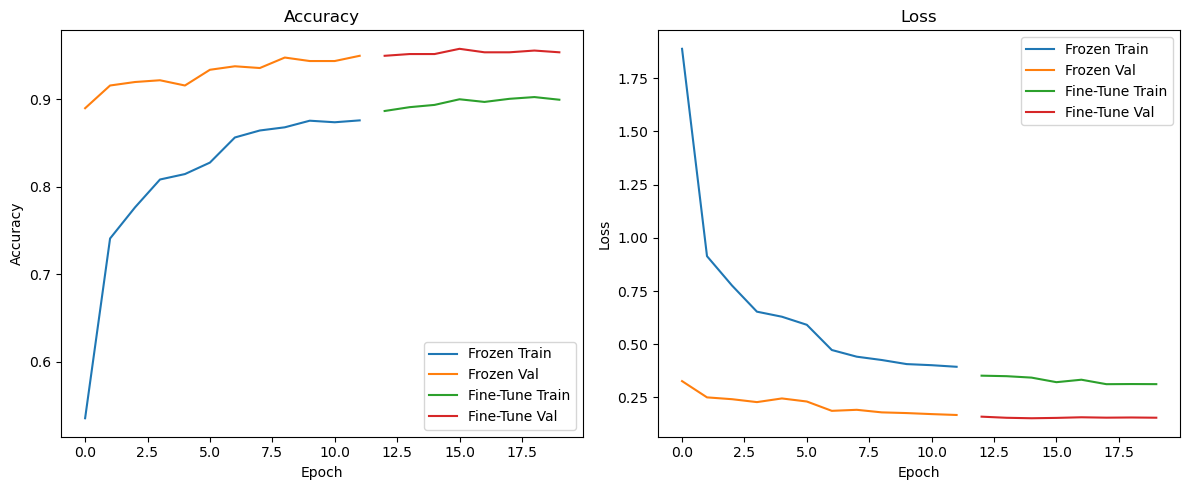

In [13]:
stages = [(history, "Frozen"), (history_fine, "Fine-Tune")]
metrics = [("accuracy", "Accuracy"), ("loss", "Loss")]

plt.figure(figsize=(12, 5))
for i, (key, title) in enumerate(metrics, start=1):
    plt.subplot(1, 2, i)
    start = 0
    for hist, name in stages:
        y_train = hist.history[key]
        y_val = hist.history["val_" + key]
        epochs = range(start, start + len(y_train))
        plt.plot(epochs, y_train, label=name + " Train")
        plt.plot(epochs, y_val, label=name + " Val")
        start += len(y_train)
    plt.xlabel("Epoch")
    plt.ylabel(title)
    plt.title(title)
    plt.legend()
plt.tight_layout()
plt.show()


Accuracy : 0.968
Precision: 0.9744285714285714
Recall   : 0.968
F1       : 0.9666435786435786
                       precision    recall  f1-score   support

           air hockey       1.00      1.00      1.00         5
      ampute football       1.00      1.00      1.00         5
              archery       0.83      1.00      0.91         5
        arm wrestling       1.00      1.00      1.00         5
         axe throwing       1.00      1.00      1.00         5
         balance beam       1.00      1.00      1.00         5
        barell racing       1.00      1.00      1.00         5
             baseball       1.00      0.80      0.89         5
           basketball       1.00      1.00      1.00         5
       baton twirling       1.00      1.00      1.00         5
            bike polo       1.00      1.00      1.00         5
            billiards       1.00      1.00      1.00         5
                  bmx       1.00      0.80      0.89         5
              bobsled  

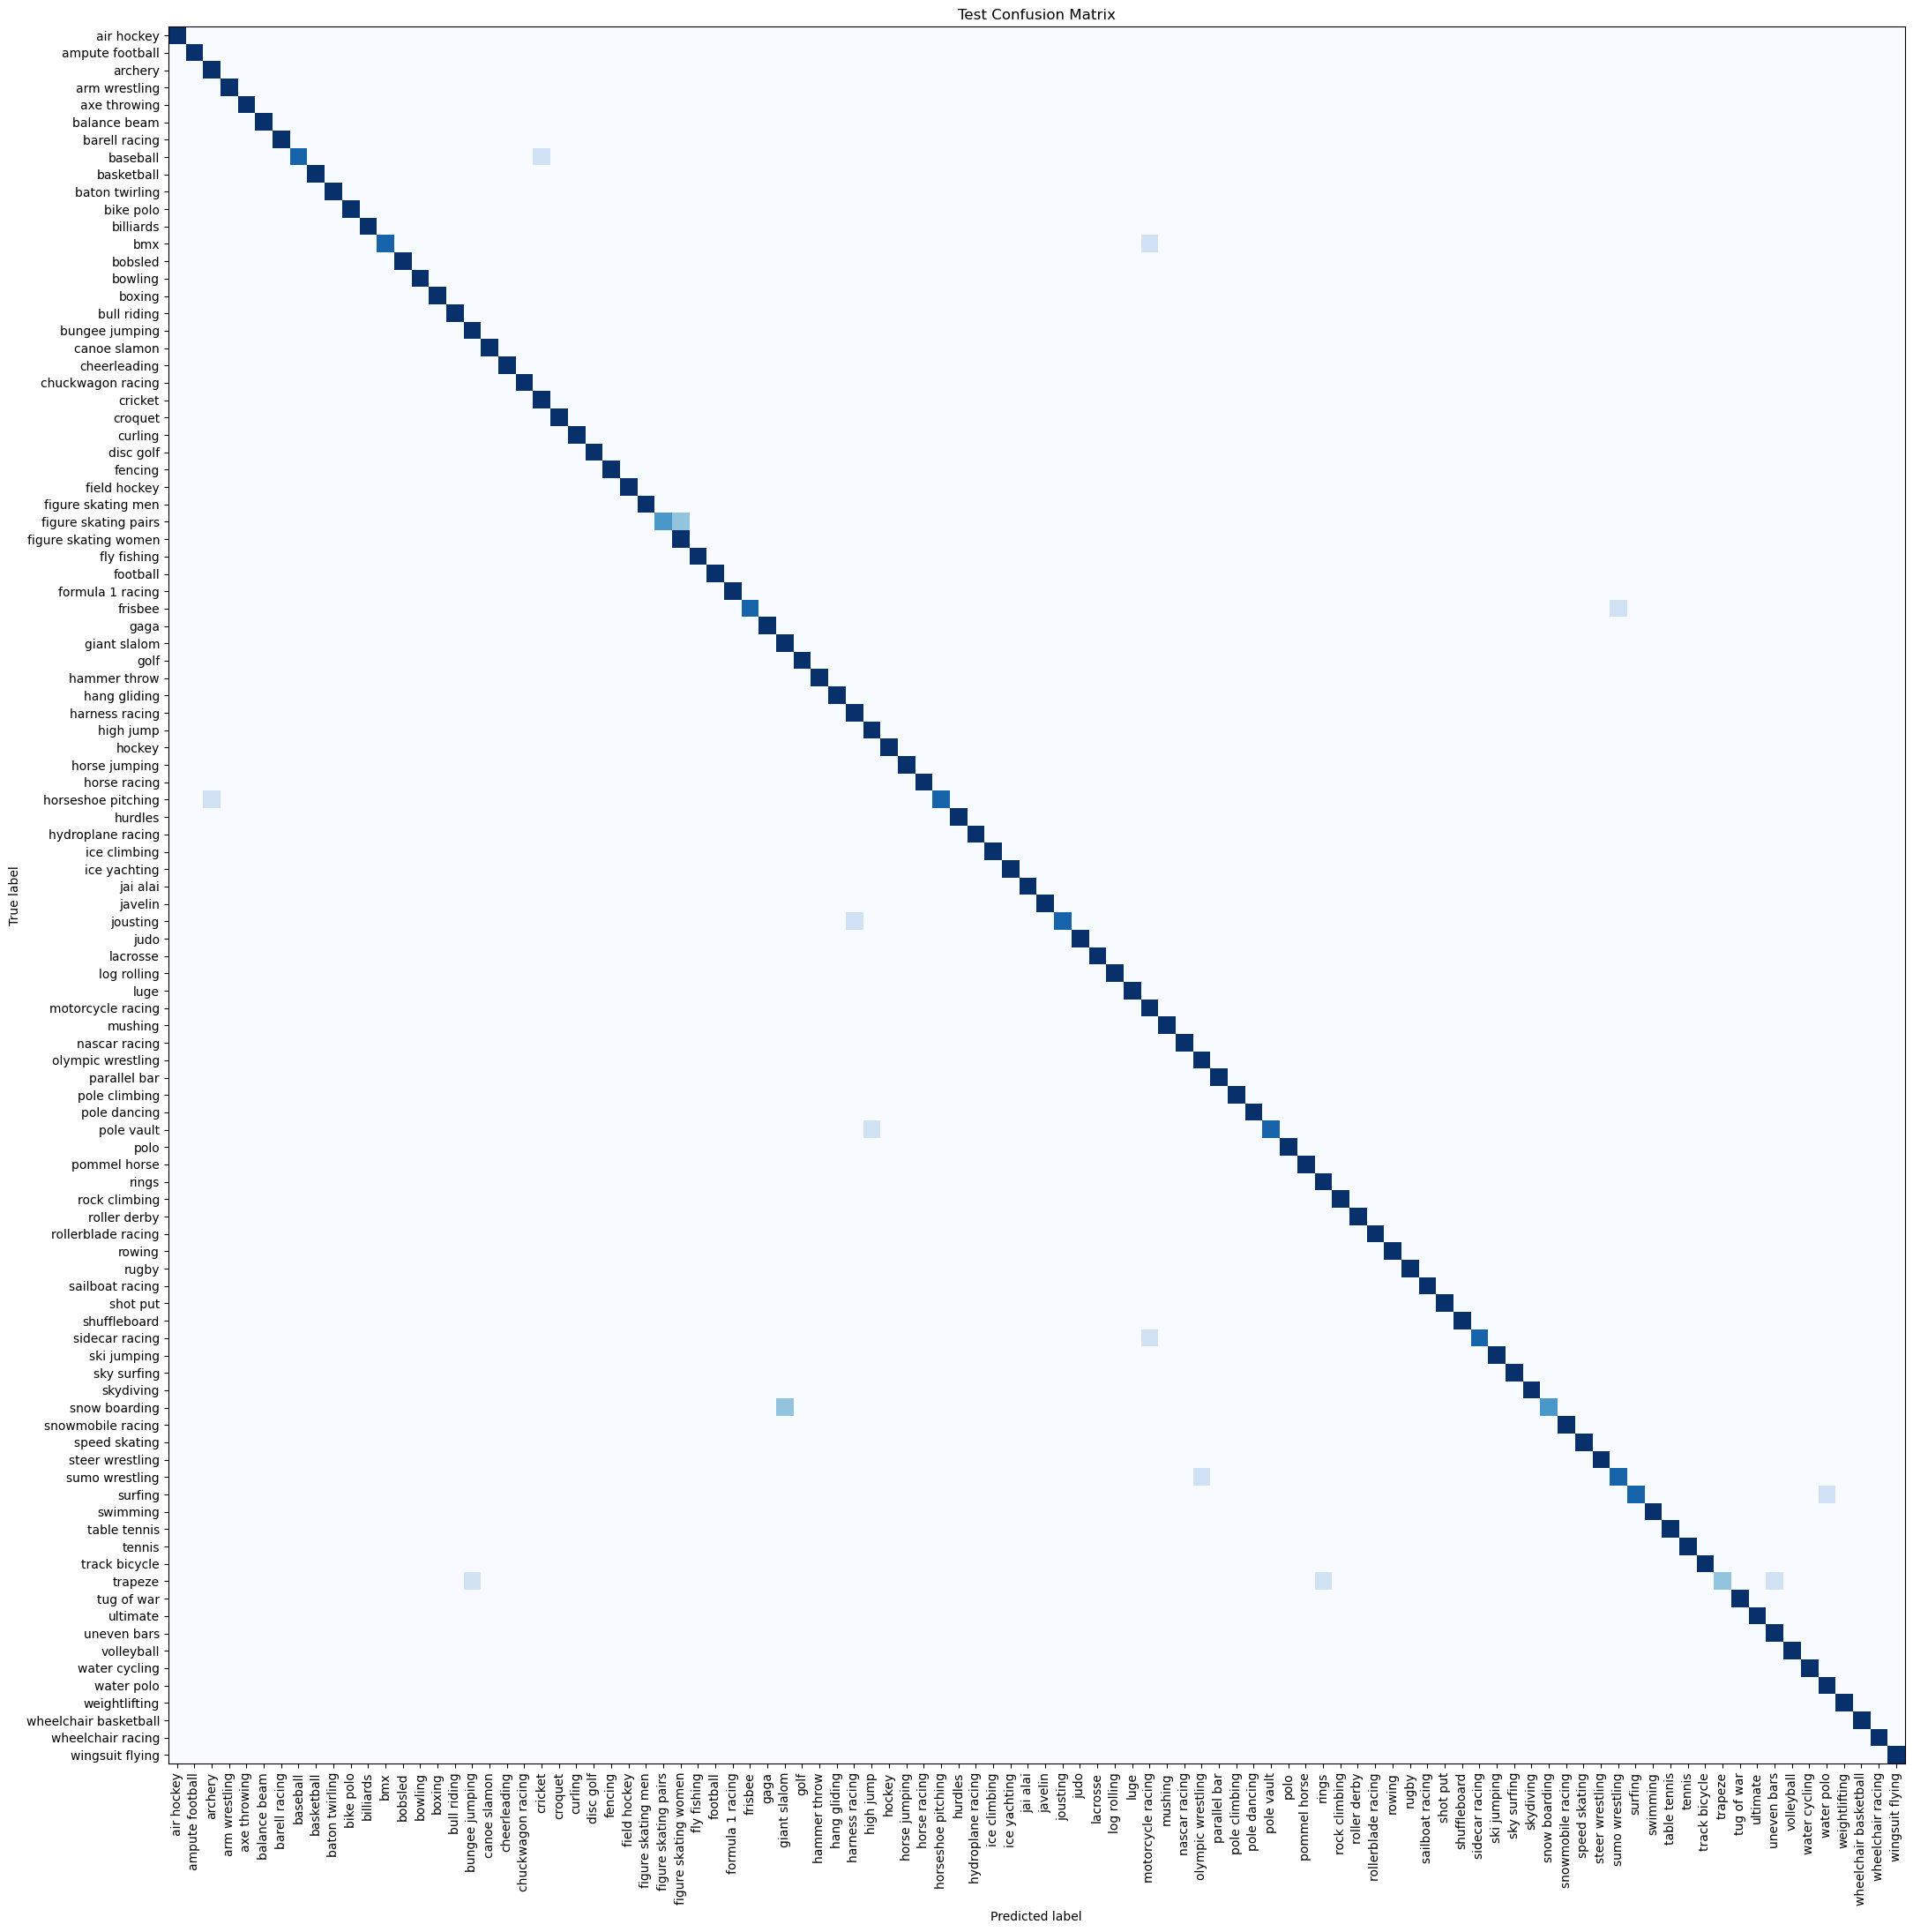

In [14]:
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, average="weighted", zero_division=0))
print("Recall   :", recall_score(y_true, y_pred, average="weighted", zero_division=0))
print("F1       :", f1_score(y_true, y_pred, average="weighted", zero_division=0))
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(22, 22))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=90, include_values=False, colorbar=False)
plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

transfer_acc = accuracy_score(y_true, y_pred)
transfer_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)


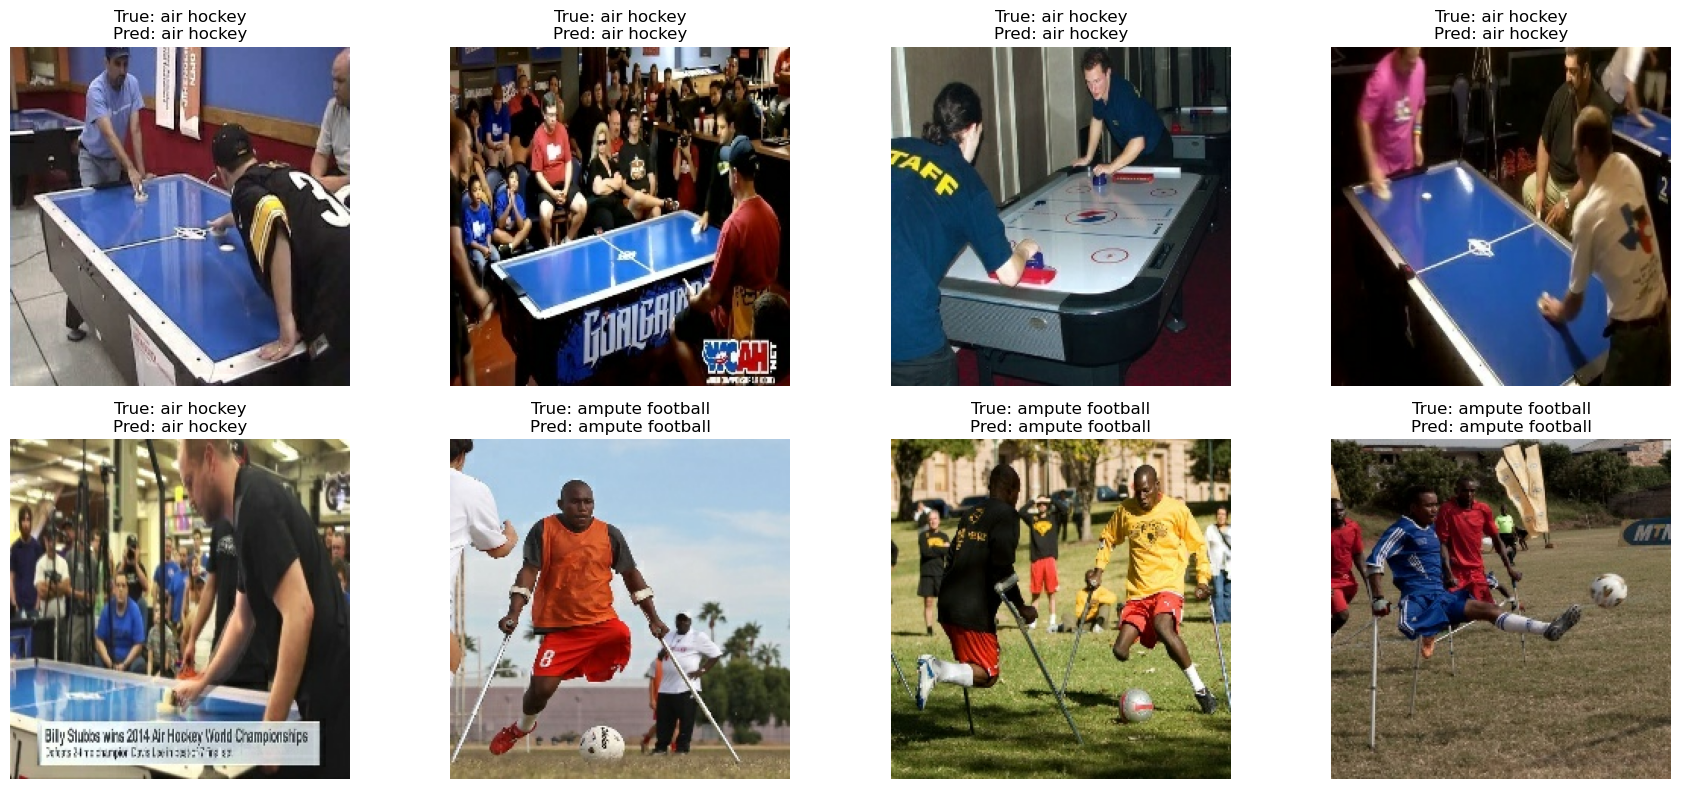

In [15]:
images, labels = next(iter(test_ds))
pred = model.predict(images, verbose=0)

plt.figure(figsize=(18, 8))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    actual = class_names[np.argmax(labels[i])]
    guessed = class_names[np.argmax(pred[i])]
    plt.title("True: " + actual + "\nPred: " + guessed)
    plt.axis("off")
plt.tight_layout()
plt.show()


## Comparison


In [18]:
print("Our CNN   Accuracy:", round(scratch_acc, 4), " F1:", round(scratch_f1, 4))
print("Transfer  Accuracy:", round(transfer_acc, 4), " F1:", round(transfer_f1, 4))


Our CNN   Accuracy: 0.502  F1: 0.4704
Transfer  Accuracy: 0.968  F1: 0.9666


In [17]:
model.save("sports_cnn.keras")


# Conclusion

We trained two models and tested them on the same test folder. Our own CNN had to learn the filters from zero. EfficientNetB0 started from ImageNet, which helps when there are 100 sports and the classes can look alike. The EfficientNet head was trained first, then the last 30 layers were fine-tuned, and we kept the run with the lower validation loss. The accuracy and F1 printed in the comparison cell show which model did better. The confusion matrix is where the weak sports show up, because one accuracy number hides them. Both models are saved.
